# Patch-Based Ablation Study

### Patch-Based Ablation Study

This study follows the same experimental setup as the Main Ablation Study, including the model architecture, training configuration, loss functions, datasets, and evaluation metrics. All experiments are conducted using the selected `2.5D_DecAtt` model. The only differences are the patch size, cropping strategy, and `USE_CROP` setting, which are adjusted across experiments to evaluate the effect of patch-based input configurations on segmentation performance.

The following parameters are used:

- `MODEL_NAME`: `2.5D_DecAtt` (fixed)
- `PATCH_SIZE`: 64, 96, 128, 160, 192, 224, 256 and 288
- `CROP_TYPE`: `center` (fixed cropping strategy)
- `USE_CROP`: `True` or `False`, depending on the experiment
- `SEEDS`: 41, 42, 43, 44, and 45

All other experimental settings remain unchanged.

In [9]:

# ============================================================
# PATCH-BASED ABLATION STUDY
# FINAL RESULTS TABLES
#
# Table 1: Main segmentation metrics
# Table 2: HD95 and empty prediction rate
#
# Full-size results: Main Ablation Study (5 seeds)
# Patch-based results: Patch Ablation Study
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from scipy.stats import t


# ============================================================
# 1. EXCEL FILE
# ============================================================

EXCEL_PATH = Path(r"Results\Patch_Ablation_Results_5Seeds.xlsx")

if not EXCEL_PATH.is_file():
    raise FileNotFoundError(
        f"Excel results file not found: {EXCEL_PATH.resolve()}"
    )

df = pd.read_excel(EXCEL_PATH)

required_columns = [
    "patch_size",
    "seed",
    "split",
    "dice",
    "iou",
    "precision",
    "recall",
    "auc",
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing Excel columns: {missing_columns}"
    )

# Use validation results only.
df["split"] = df["split"].astype(str).str.strip().str.lower()
df = df[df["split"] == "val"].copy()

if df.empty:
    raise ValueError("No validation results were found in the Excel file.")

# Ensure numerical values.
numeric_columns = [
    "patch_size",
    "seed",
    "dice",
    "iou",
    "precision",
    "recall",
    "auc",
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=numeric_columns)

# Check duplicate records.
if df.duplicated(subset=["patch_size", "seed"]).any():
    raise ValueError(
        "Duplicate patch_size/seed validation records were found."
    )


# ============================================================
# 2. CONFIDENCE INTERVAL FUNCTION
# ============================================================

def mean_ci(values, confidence=0.95):

    values = np.asarray(values, dtype=np.float64)
    values = values[np.isfinite(values)]

    n = len(values)

    if n == 0:
        return np.nan, np.nan

    mean = values.mean()

    if n == 1:
        return mean, np.nan

    sd = values.std(ddof=1)
    t_critical = t.ppf(
        (1 + confidence) / 2,
        df=n - 1,
    )

    ci = t_critical * sd / np.sqrt(n)

    return mean, ci


def format_mean_ci(values, decimals=2):

    mean, ci = mean_ci(values)

    if np.isnan(mean):
        return "—"

    if np.isnan(ci):
        return f"{mean:.{decimals}f} ± —"

    return f"{mean:.{decimals}f} ± {ci:.{decimals}f}"


# ============================================================
# 3. PATCH SIZES AND DISPLAY ORDER
# ============================================================

PATCH_SIZES = [288, 256, 224, 192, 160, 128, 96, 64]

TABLE_ORDER = [
    "Full size (320×320)",
    "288×288",
    "256×256",
    "224×224",
    "192×192",
    "160×160",
    "128×128",
    "96×96",
    "64×64",
]


# ============================================================
# 4. FULL-SIZE RESULTS
# Main Ablation Study: Mean ± 95% CI
# ============================================================

FULL_SIZE_MAIN = {
    "dice": "74.88 ± 2.18",
    "iou": "59.87 ± 2.79",
    "precision": "80.57 ± 1.00",
    "recall": "69.99 ± 3.69",
    "auc": "92.52 ± 1.62",
}


# ============================================================
# 5. TABLE 1 — MAIN SEGMENTATION METRICS
# ============================================================

metric_columns = {
    "dice": "Dice (%)",
    "iou": "IoU (%)",
    "precision": "Precision (%)",
    "recall": "Sensitivity (%)",
    "auc": "AUC (%)",
}

table1_rows = []

# Full-size row.
full_row = {
    "Input size": "Full size (320×320)",
}

for metric, column_name in metric_columns.items():
    full_row[column_name] = FULL_SIZE_MAIN[metric]

table1_rows.append(full_row)


# Patch-based rows.
for patch_size in PATCH_SIZES:

    patch_df = df[df["patch_size"] == patch_size]

    if patch_df.empty:
        raise ValueError(
            f"No validation results found for patch size {patch_size}."
        )

    seeds_found = sorted(patch_df["seed"].unique())

    if len(seeds_found) != 5:
        print(
            f"WARNING: Patch {patch_size}×{patch_size} "
            f"has {len(seeds_found)} seeds: {seeds_found}"
        )

    row = {
        "Input size": f"{patch_size}×{patch_size}"
    }

    for metric, column_name in metric_columns.items():

        values = patch_df[metric].to_numpy(dtype=np.float64)

        # Convert metrics from [0, 1] to percentage.
        values = values * 100

        row[column_name] = format_mean_ci(
            values,
            decimals=2,
        )

    table1_rows.append(row)


table1 = pd.DataFrame(table1_rows)

table1["Input size"] = pd.Categorical(
    table1["Input size"],
    categories=TABLE_ORDER,
    ordered=True,
)

table1 = (
    table1
    .sort_values("Input size")
    .reset_index(drop=True)
)

table1["Input size"] = table1["Input size"].astype(str)


print("\n" + "=" * 100)
print("TABLE 1 — MAIN SEGMENTATION PERFORMANCE")
print("Mean ± 95% CI")
print("=" * 100)

display(table1)


# ============================================================
# 6. PATCH-BASED HD95 AND EMPTY PREDICTION RESULTS
# Four available seeds: 41, 43, 44, 45
# ============================================================

patch_evaluation = {

    64: {
        "dice": [0.8372, 0.8378, 0.8370, 0.8404],
        "hd95": [2.2484, 2.2559, 2.2678, 2.2266],
        "empty_rate": [0.00, 0.00, 0.00, 0.00],
        "valid_hd95": [2082, 2082, 2082, 2082],
    },

    96: {
        "dice": [0.8452, 0.8395, 0.8369, 0.8400],
        "hd95": [2.1600, 2.2514, 2.3056, 2.2599],
        "empty_rate": [0.00, 0.00, 0.00, 0.00],
        "valid_hd95": [2082, 2082, 2082, 2082],
    },

    128: {
        "dice": [0.8376, 0.8377, 0.8361, 0.8461],
        "hd95": [2.2845, 2.2662, 2.3541, 2.1652],
        "empty_rate": [0.00, 0.10, 0.00, 0.05],
        "valid_hd95": [2082, 2080, 2082, 2081],
    },

    160: {
        "dice": [0.8277, 0.8245, 0.8233, 0.8245],
        "hd95": [2.6101, 2.5474, 2.6141, 2.5474],
        "empty_rate": [0.34, 0.72, 0.43, 0.72],
        "valid_hd95": [2075, 2067, 2073, 2067],
    },

    192: {
        "dice": [0.8117, 0.8084, 0.8065, 0.8085],
        "hd95": [3.4724, 4.1823, 3.7928, 3.3963],
        "empty_rate": [0.24, 0.24, 0.48, 1.01],
        "valid_hd95": [2077, 2077, 2072, 2061],
    },

    224: {
        "dice": [0.7911, 0.7970, 0.7899, 0.7899],
        "hd95": [3.4358, 3.4833, 4.8837, 4.8837],
        "empty_rate": [1.87, 1.34, 0.67, 0.67],
        "valid_hd95": [2043, 2054, 2068, 2068],
    },

    256: {
        "dice": [0.7523, 0.7411, 0.7397, 0.7485],
        "hd95": [7.0545, 7.9021, 6.3649, 6.6234],
        "empty_rate": [3.12, 4.23, 4.37, 2.93],
        "valid_hd95": [2017, 1994, 1991, 2021],
    },

    288: {
        "dice": [0.7208, 0.7126, 0.7161, 0.7311],
        "hd95": [11.0994, 8.9936, 7.5456, 8.7342],
        "empty_rate": [4.18, 5.57, 6.63, 3.75],
        "valid_hd95": [1995, 1966, 1944, 2004],
    },
}


# ============================================================
# 7. TABLE 2 — HD95 AND EMPTY PREDICTION RATE
# ============================================================

FULL_SIZE_BOUNDARY = {
    "dice": "74.88 ± 2.18",
    "hd95": "19.34 ± 4.68",
    "empty_rate": "10.58 ± 1.10",
    "valid_hd95": "—",
}

table2_rows = []

# Full-size row.
table2_rows.append({
    "Input size": "Full size (320×320)",
    "Dice (%)": FULL_SIZE_BOUNDARY["dice"],
    "HD95 (px)": FULL_SIZE_BOUNDARY["hd95"],
    "Empty prediction rate (%)": FULL_SIZE_BOUNDARY["empty_rate"],
    "Valid HD95 samples": FULL_SIZE_BOUNDARY["valid_hd95"],
})


# Patch-based rows.
for patch_size in PATCH_SIZES:

    results = patch_evaluation[patch_size]

    dice_values = np.asarray(results["dice"]) * 100
    hd95_values = np.asarray(results["hd95"])
    empty_values = np.asarray(results["empty_rate"])
    valid_values = np.asarray(results["valid_hd95"])

    table2_rows.append({
        "Input size": f"{patch_size}×{patch_size}",
        "Dice (%)": format_mean_ci(dice_values, decimals=2),
        "HD95 (px)": format_mean_ci(hd95_values, decimals=2),
        "Empty prediction rate (%)": format_mean_ci(
            empty_values,
            decimals=2,
        ),
        "Valid HD95 samples": format_mean_ci(
            valid_values,
            decimals=1,
        ),
    })


table2 = pd.DataFrame(table2_rows)

table2["Input size"] = pd.Categorical(
    table2["Input size"],
    categories=TABLE_ORDER,
    ordered=True,
)

table2 = (
    table2
    .sort_values("Input size")
    .reset_index(drop=True)
)

table2["Input size"] = table2["Input size"].astype(str)


print("\n" + "=" * 110)
print("TABLE 2 — HD95 AND EMPTY PREDICTION RATE")
print("Mean ± 95% CI")
print("=" * 110)

display(table2)


# ============================================================
# 8. SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("PATCH-BASED ABLATION TABLES COMPLETED")
print("=" * 80)

print(f"Table 1 rows: {len(table1)}")
print(f"Table 2 rows: {len(table2)}")

print("\nTable 1: Main segmentation metrics")
print("Table 2: HD95 and empty prediction rate")

print("\nConfidence intervals:")
print("- Full-size results: 5 seeds")
print("- Patch-based main metrics: based on available Excel seeds (5 seeds)")
print("- Patch-based HD95 and empty rate: 4 seeds (41, 43, 44, 45)")



TABLE 1 — MAIN SEGMENTATION PERFORMANCE
Mean ± 95% CI


,Input size,Dice (%),IoU (%),Precision (%),Sensitivity (%),AUC (%)
0,Full size (320×320),74.88 ± 2.18,59.87 ± 2.79,80.57 ± 1.00,69.99 ± 3.69,92.52 ± 1.62
1,288×288,79.37 ± 0.21,65.80 ± 0.29,82.51 ± 1.35,76.49 ± 1.32,94.88 ± 1.41
2,256×256,80.14 ± 0.48,66.86 ± 0.67,80.82 ± 1.10,79.48 ± 1.45,95.58 ± 1.07
3,224×224,83.32 ± 0.33,71.42 ± 0.48,84.87 ± 1.73,81.86 ± 1.21,97.23 ± 0.74
4,192×192,84.06 ± 0.32,72.50 ± 0.47,82.78 ± 1.54,85.41 ± 1.51,98.11 ± 0.70
5,160×160,85.46 ± 0.17,74.61 ± 0.26,84.77 ± 1.41,86.18 ± 1.51,98.43 ± 0.70
6,128×128,86.13 ± 0.44,75.64 ± 0.68,86.04 ± 1.14,86.24 ± 1.60,99.01 ± 0.63
7,96×96,85.99 ± 0.40,75.42 ± 0.62,85.32 ± 0.91,86.68 ± 1.19,99.15 ± 0.50
8,64×64,85.95 ± 0.13,75.36 ± 0.20,84.75 ± 1.06,87.20 ± 1.06,99.39 ± 0.12



TABLE 2 — HD95 AND EMPTY PREDICTION RATE
Mean ± 95% CI


,Input size,Dice (%),HD95 (px),Empty prediction rate (%),Valid HD95 samples
0,Full size (320×320),74.88 ± 2.18,19.34 ± 4.68,10.58 ± 1.10,—
1,288×288,72.02 ± 1.28,9.09 ± 2.35,5.03 ± 2.10,1977.2 ± 43.7
2,256×256,74.54 ± 0.96,6.99 ± 1.07,3.66 ± 1.18,2005.8 ± 24.6
3,224×224,79.20 ± 0.54,4.17 ± 1.31,1.14 ± 0.93,2058.2 ± 19.3
4,192×192,80.88 ± 0.34,3.71 ± 0.57,0.49 ± 0.58,2071.8 ± 12.0
5,160×160,82.50 ± 0.30,2.58 ± 0.06,0.55 ± 0.31,2070.5 ± 6.6
6,128×128,83.94 ± 0.72,2.27 ± 0.12,0.04 ± 0.08,2081.2 ± 1.5
7,96×96,84.04 ± 0.55,2.24 ± 0.10,0.00 ± 0.00,2082.0 ± 0.0
8,64×64,83.81 ± 0.25,2.25 ± 0.03,0.00 ± 0.00,2082.0 ± 0.0



PATCH-BASED ABLATION TABLES COMPLETED
Table 1 rows: 9
Table 2 rows: 9

Table 1: Main segmentation metrics
Table 2: HD95 and empty prediction rate

Confidence intervals:
- Full-size results: 5 seeds
- Patch-based main metrics: based on available Excel seeds (5 seeds)
- Patch-based HD95 and empty rate: 4 seeds (41, 43, 44, 45)


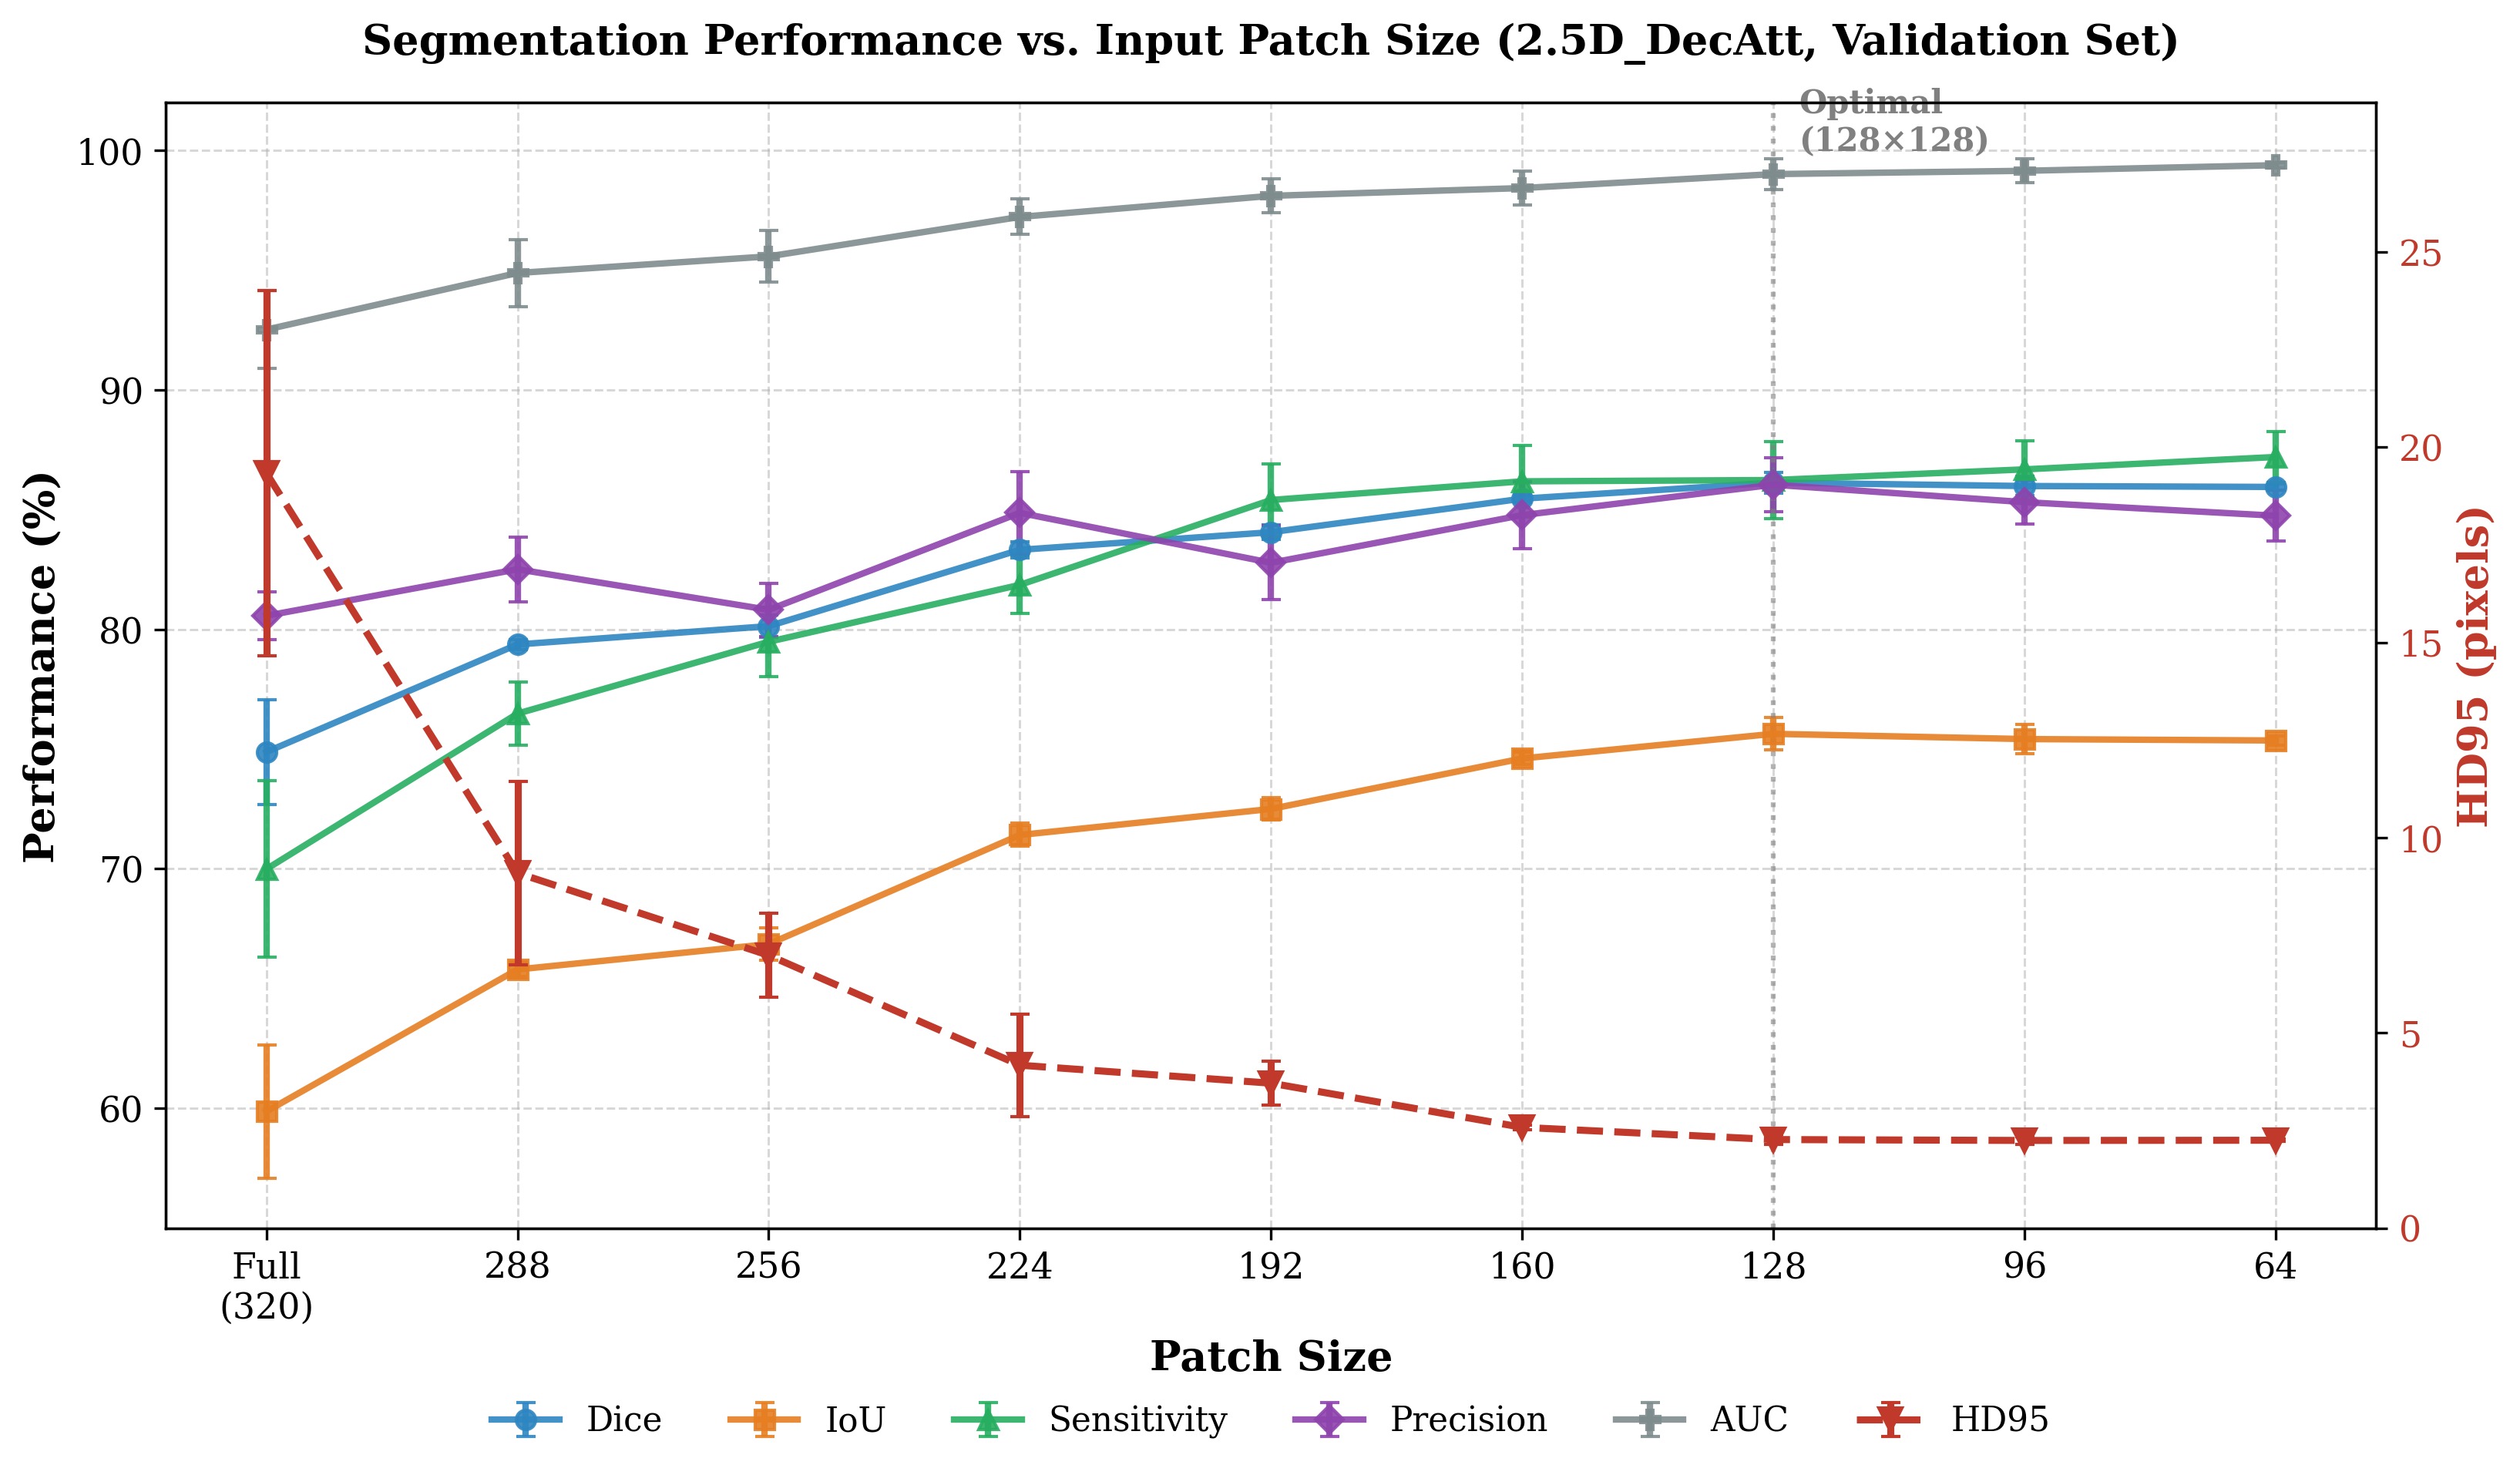

Figure saved: Fig9_PatchSize_Analysis.png

FIGURE DATA — MEAN ± 95% CI


,Input size,Dice,IoU,Sensitivity,Precision,AUC,HD95 (px)
0,Full (320),74.88 ± 2.18,59.87 ± 2.79,69.99 ± 3.69,80.57 ± 1.00,92.52 ± 1.62,19.34 ± 4.68
1,288,79.37 ± 0.21,65.80 ± 0.29,76.49 ± 1.32,82.51 ± 1.35,94.88 ± 1.41,9.09 ± 2.35
2,256,80.14 ± 0.48,66.86 ± 0.67,79.48 ± 1.45,80.82 ± 1.10,95.58 ± 1.07,6.99 ± 1.07
3,224,83.32 ± 0.33,71.42 ± 0.48,81.86 ± 1.21,84.87 ± 1.73,97.23 ± 0.74,4.17 ± 1.31
4,192,84.06 ± 0.32,72.50 ± 0.47,85.41 ± 1.51,82.78 ± 1.54,98.11 ± 0.70,3.71 ± 0.57
5,160,85.46 ± 0.17,74.61 ± 0.26,86.18 ± 1.51,84.77 ± 1.41,98.43 ± 0.70,2.58 ± 0.06
6,128,86.13 ± 0.44,75.64 ± 0.68,86.24 ± 1.60,86.04 ± 1.14,99.01 ± 0.63,2.27 ± 0.12
7,96,85.99 ± 0.40,75.42 ± 0.62,86.68 ± 1.19,85.32 ± 0.91,99.15 ± 0.50,2.24 ± 0.10
8,64,85.95 ± 0.13,75.36 ± 0.20,87.20 ± 1.06,84.75 ± 1.06,99.39 ± 0.12,2.25 ± 0.03


In [12]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

from pathlib import Path
from scipy.stats import t


# =========================================================
# 1. LOAD EXCEL RESULTS
# =========================================================

EXCEL_PATH = Path(r"Results\Patch_Ablation_Results_5Seeds.xlsx")

if not EXCEL_PATH.is_file():
    raise FileNotFoundError(
        f"Excel file not found: {EXCEL_PATH.resolve()}"
    )

df = pd.read_excel(EXCEL_PATH)

required_columns = [
    "patch_size",
    "seed",
    "split",
    "dice",
    "iou",
    "precision",
    "recall",
    "auc",
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in Excel file: {missing_columns}"
    )

df["split"] = df["split"].astype(str).str.strip().str.lower()
df = df[df["split"] == "val"].copy()

for col in required_columns:
    if col != "split":
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=required_columns)

if df.duplicated(subset=["patch_size", "seed"]).any():
    raise ValueError(
        "Duplicate patch_size/seed validation records were found."
    )


# =========================================================
# 2. CONFIDENCE INTERVAL FUNCTION
# =========================================================

def mean_ci(values, confidence=0.95):

    values = np.asarray(values, dtype=np.float64)
    values = values[np.isfinite(values)]

    n = len(values)

    if n == 0:
        return np.nan, np.nan

    mean = values.mean()

    if n == 1:
        return mean, np.nan

    sd = values.std(ddof=1)

    t_critical = t.ppf(
        (1 + confidence) / 2,
        df=n - 1,
    )

    ci = t_critical * sd / np.sqrt(n)

    return mean, ci


# =========================================================
# 3. PATCH SIZES
# =========================================================

patch_sizes = [
    "Full\n(320)",
    "288",
    "256",
    "224",
    "192",
    "160",
    "128",
    "96",
    "64",
]

numeric_patch_sizes = [288, 256, 224, 192, 160, 128, 96, 64]


# =========================================================
# 4. FULL-SIZE RESULTS
# Main Ablation Study: Mean ± 95% CI
# =========================================================

full_size = {
    "Dice": (74.88, 2.18),
    "IoU": (59.87, 2.79),
    "Sensitivity": (69.99, 3.69),
    "Precision": (80.57, 1.00),
    "AUC": (92.52, 1.62),
    "HD95": (19.34, 4.68),
}


# =========================================================
# 5. PATCH-BASED HD95 RESULTS
# Four available seeds: 41, 43, 44, 45
# =========================================================

patch_evaluation = {

    64: {
        "hd95": [2.2484, 2.2559, 2.2678, 2.2266],
    },

    96: {
        "hd95": [2.1600, 2.2514, 2.3056, 2.2599],
    },

    128: {
        "hd95": [2.2845, 2.2662, 2.3541, 2.1652],
    },

    160: {
        "hd95": [2.6101, 2.5474, 2.6141, 2.5474],
    },

    192: {
        "hd95": [3.4724, 4.1823, 3.7928, 3.3963],
    },

    224: {
        "hd95": [3.4358, 3.4833, 4.8837, 4.8837],
    },

    256: {
        "hd95": [7.0545, 7.9021, 6.3649, 6.6234],
    },

    288: {
        "hd95": [11.0994, 8.9936, 7.5456, 8.7342],
    },
}


# =========================================================
# 6. EXTRACT MEAN AND 95% CI FROM EXCEL
# =========================================================

metric_mapping = {
    "Dice": "dice",
    "IoU": "iou",
    "Sensitivity": "recall",
    "Precision": "precision",
    "AUC": "auc",
}

data = {
    "Dice": [],
    "IoU": [],
    "Sensitivity": [],
    "Precision": [],
    "AUC": [],
    "HD95": [],
}

error_data = {
    "Dice": [],
    "IoU": [],
    "Sensitivity": [],
    "Precision": [],
    "AUC": [],
    "HD95": [],
}


# Full-size results.
for metric in metric_mapping:

    mean, ci = full_size[metric]

    data[metric].append(mean)
    error_data[metric].append(ci)

mean, ci = full_size["HD95"]

data["HD95"].append(mean)
error_data["HD95"].append(ci)


# Patch-based results.
for patch_size in numeric_patch_sizes:

    patch_df = df[df["patch_size"] == patch_size]

    if patch_df.empty:
        raise ValueError(
            f"No validation results found for patch size {patch_size}."
        )

    seeds_found = sorted(patch_df["seed"].unique())

    if len(seeds_found) != 5:
        print(
            f"WARNING: Patch {patch_size}×{patch_size} "
            f"has {len(seeds_found)} seeds: {seeds_found}"
        )

    # Main segmentation metrics from Excel.
    for metric, excel_column in metric_mapping.items():

        values = patch_df[excel_column].to_numpy(dtype=np.float64)

        # Convert values from [0, 1] to percentage.
        values = values * 100

        mean, ci = mean_ci(values)

        data[metric].append(mean)
        error_data[metric].append(ci)

    # HD95 from per-seed evaluation results.
    hd95_values = patch_evaluation[patch_size]["hd95"]

    mean, ci = mean_ci(hd95_values)

    data["HD95"].append(mean)
    error_data["HD95"].append(ci)


# =========================================================
# 7. CONVERT RESULTS TO NUMPY ARRAYS
# =========================================================

for metric in data:

    data[metric] = np.asarray(
        data[metric],
        dtype=np.float64,
    )

    error_data[metric] = np.asarray(
        error_data[metric],
        dtype=np.float64,
    )


# =========================================================
# 8. PLOT STYLE
# =========================================================

mpl.rcParams["font.family"] = "serif"
mpl.rcParams["axes.labelsize"] = 13
mpl.rcParams["xtick.labelsize"] = 11
mpl.rcParams["ytick.labelsize"] = 11

x = np.arange(len(patch_sizes))

fig, ax1 = plt.subplots(
    figsize=(11, 6.5),
    dpi=300,
)

ax2 = ax1.twinx()


# =========================================================
# 9. LEFT AXIS — PERCENTAGE METRICS
# =========================================================

metrics_left = [
    ("Dice", "#2E86C1", "o"),
    ("IoU", "#E67E22", "s"),
    ("Sensitivity", "#27AE60", "^"),
    ("Precision", "#8E44AD", "D"),
    ("AUC", "#7F8C8D", "P"),
]

for name, color, marker in metrics_left:

    ax1.errorbar(
        x,
        data[name],
        yerr=error_data[name],
        marker=marker,
        markersize=6,
        linewidth=2,
        color=color,
        label=name,
        capsize=3,
        alpha=0.9,
    )

ax1.set_xlabel(
    "Patch Size",
    fontweight="bold",
)

ax1.set_ylabel(
    "Performance (%)",
    fontweight="bold",
)

ax1.set_xticks(x)
ax1.set_xticklabels(patch_sizes)
ax1.set_ylim(55, 102)


# =========================================================
# 10. RIGHT AXIS — HD95
# =========================================================

ax2.errorbar(
    x,
    data["HD95"],
    yerr=error_data["HD95"],
    marker="v",
    markersize=7,
    linewidth=2.2,
    color="#C0392B",
    label="HD95",
    capsize=3,
    linestyle="--",
)

ax2.set_ylabel(
    "HD95 (pixels)",
    fontweight="bold",
    color="#C0392B",
)

ax2.tick_params(
    axis="y",
    labelcolor="#C0392B",
)

# Set the upper limit based on the observed values and CI.
hd95_upper = np.max(
    data["HD95"] + error_data["HD95"]
)

ax2.set_ylim(
    0,
    max(25, hd95_upper * 1.2),
)

ax2.grid(False)


# =========================================================
# 11. MARK THE SELECTED PATCH SIZE
# =========================================================

best_idx = patch_sizes.index("128")

ax1.axvline(
    x=best_idx,
    color="gray",
    linestyle=":",
    linewidth=1.5,
    alpha=0.6,
)

ax1.text(
    best_idx + 0.1,
    100,
    "Optimal\n(128×128)",
    fontsize=10,
    color="gray",
    fontweight="bold",
)


# =========================================================
# 12. COMBINED LEGEND
# =========================================================

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=6,
    frameon=False,
    fontsize=10.5,
)


# =========================================================
# 13. TITLE AND LAYOUT
# =========================================================

ax1.set_title(
    "Segmentation Performance vs. Input Patch Size "
    "(2.5D_DecAtt, Validation Set)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
# =========================================================
# GRID LINES
# =========================================================

ax1.grid(
    True,
    axis="both",
    linestyle="--",
    linewidth=0.7,
    alpha=0.5,
)

ax2.grid(False)

plt.tight_layout()


# =========================================================
# 14. SAVE FIGURE
# =========================================================

OUTPUT_PATH = "Fig9_PatchSize_Analysis.png"

plt.savefig(
    OUTPUT_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Figure saved: {OUTPUT_PATH}")


# =========================================================
# 15. DISPLAY NUMERICAL SUMMARY
# =========================================================

summary_rows = []

for i, patch_label in enumerate(patch_sizes):

    row = {
        "Input size": patch_label.replace("\n", " "),
    }

    for metric in metric_mapping:

        row[metric] = (
            f"{data[metric][i]:.2f} ± "
            f"{error_data[metric][i]:.2f}"
        )

    row["HD95 (px)"] = (
        f"{data['HD95'][i]:.2f} ± "
        f"{error_data['HD95'][i]:.2f}"
    )

    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)

print("\nFIGURE DATA — MEAN ± 95% CI")
display(summary_df)


--------------

### Contrast–ΔDice Correlation Analysis Across Patch Sizes

This analysis examines the relationship between nodule-to-background intensity contrast and changes in segmentation performance across different patch sizes. The full-size model (320×320) was used as the reference, and the Dice score differences (ΔDice) were calculated for each patch-based configuration relative to this reference. Pearson and Spearman correlation coefficients were computed using the 2,016 test samples to assess the association between nodule contrast and segmentation improvements. The results are presented in Fig. 11, Fig. 12, and Table 13.

,patch_size,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,320,2016,NaN,NaN,NaN,NaN
1,288,2016,-0.085025,1.322801e-04,0.004256,8.485431e-01
2,256,2016,-0.140271,2.523479e-10,-0.056032,1.186102e-02
3,224,2016,-0.168322,2.798862e-14,-0.148570,2.029572e-11
4,192,2016,-0.223812,2.639153e-24,-0.249700,4.945859e-30
5,160,2016,-0.249222,6.400449e-30,-0.249090,6.871903e-30
6,128,2016,-0.245876,3.836708e-29,-0.192169,3.196230e-18
7,96,2016,-0.252000,1.418075e-30,-0.215202,1.495928e-22
8,64,2016,-0.258207,4.571246e-32,-0.217143,6.111367e-23


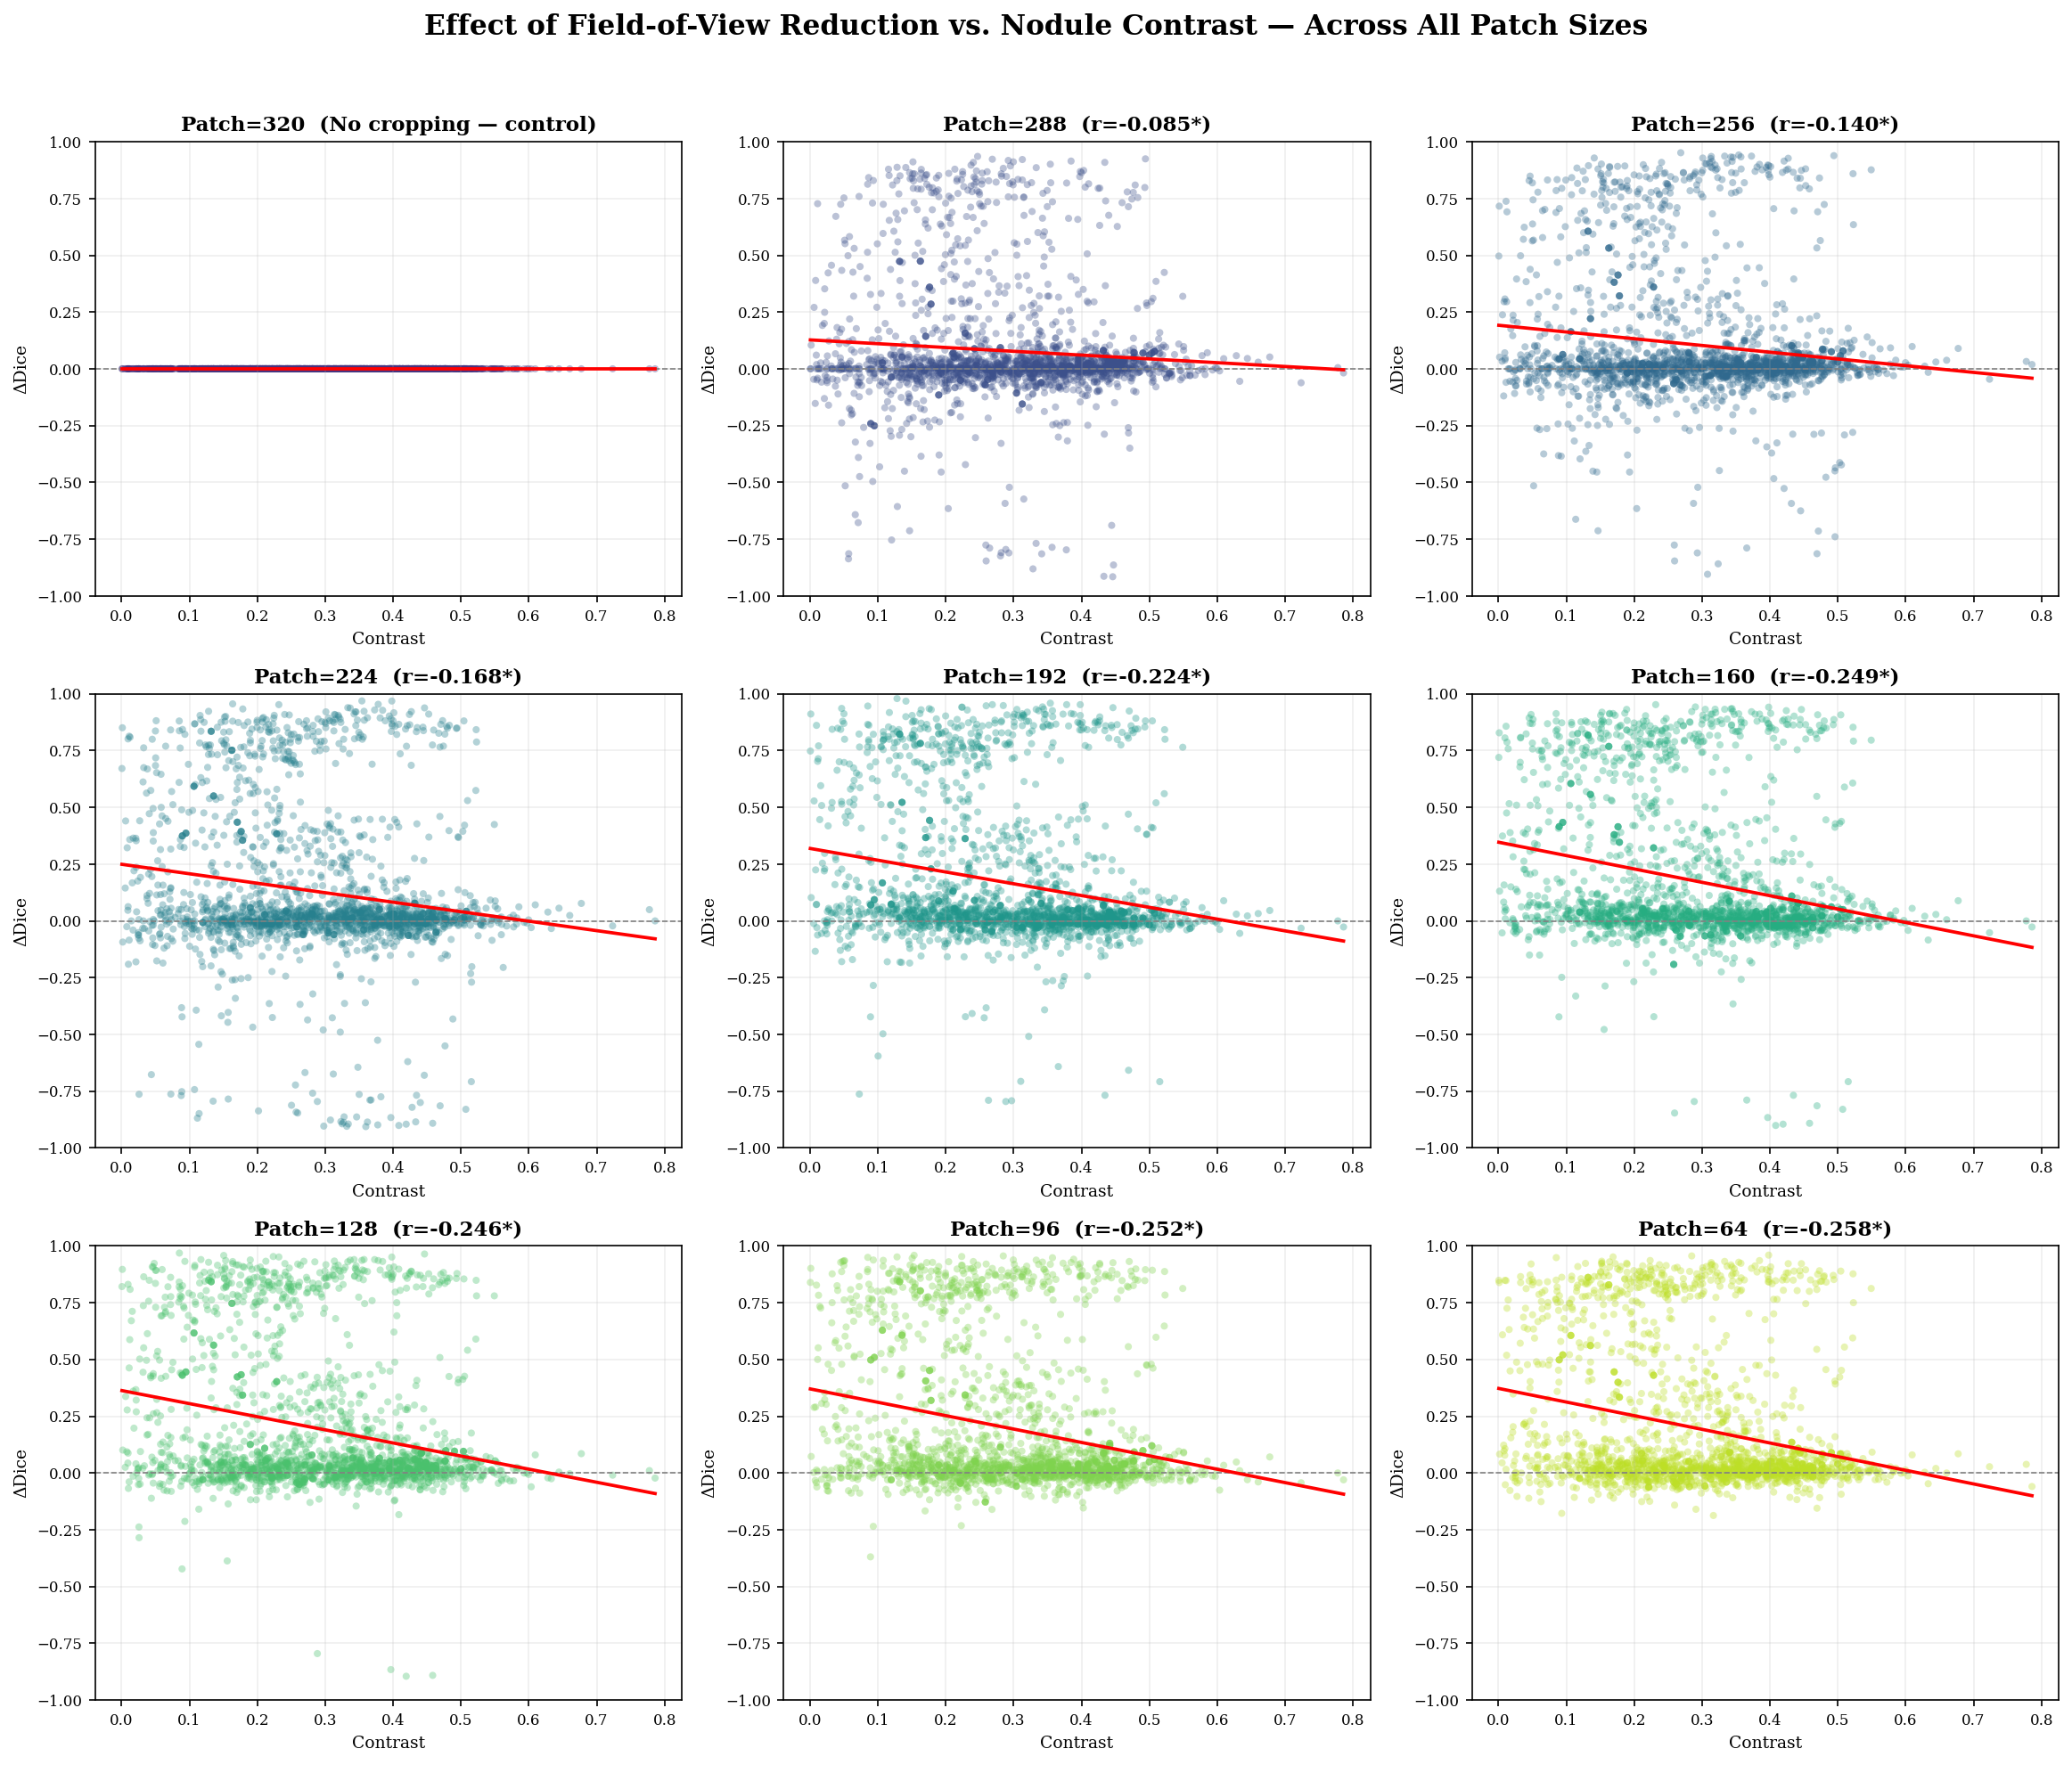

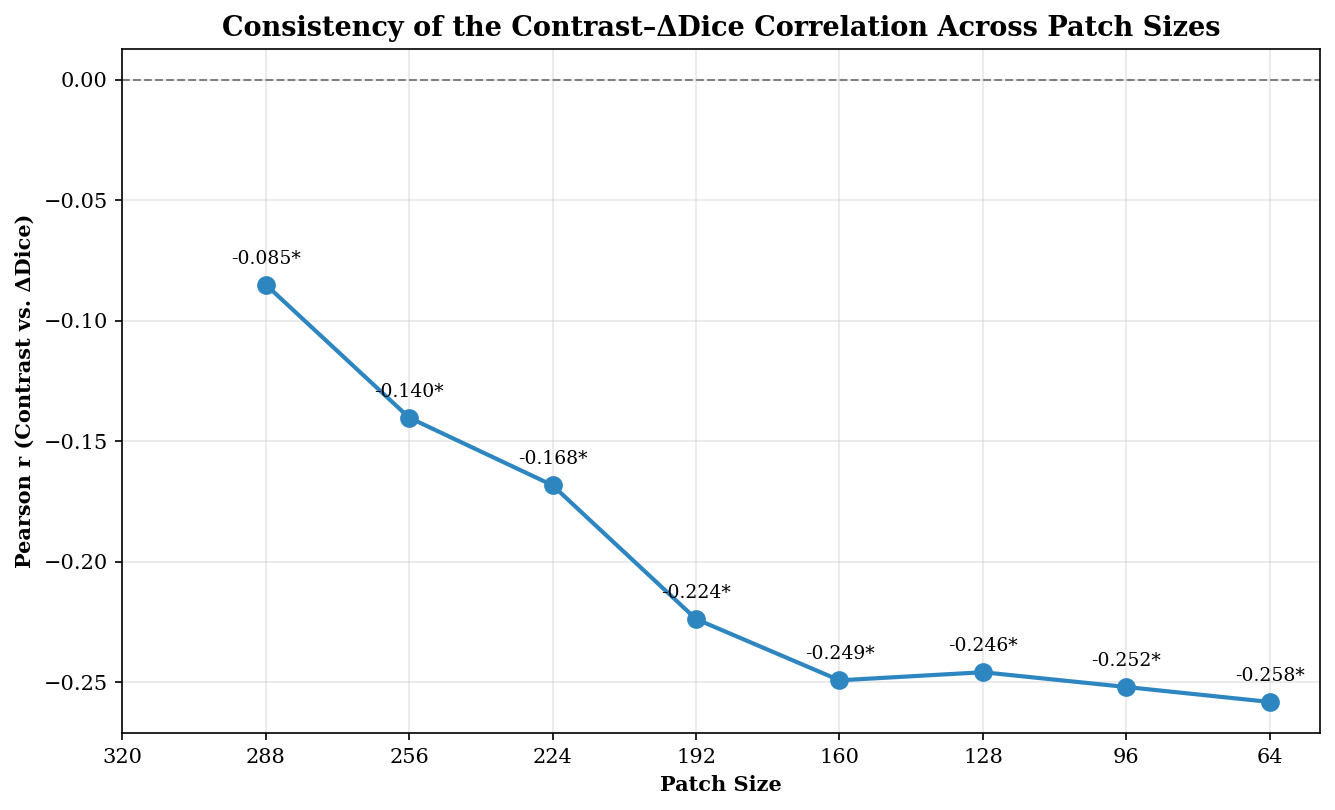

In [ ]:
# ============================================================
# Contrast–ΔDice Correlation Analysis Across Patch Sizes
# ============================================================
# This cell evaluates the relationship between nodule-to-background
# contrast and the change in Dice score (ΔDice) for each patch size.
#
# The full-size model is evaluated once and used as the reference.
# Each patch-based model is then evaluated using the same test samples
# and ROI-based cropping configuration used in the patch-size study.
#
# Outputs:
#   1. Correlation_Summary_AllPatchSizes.csv
#   2. Correlation_AllPatchSizes_Grid.png
#   3. Correlation_Trend_AllPatchSizes.png
#
# Prerequisites:
#   - SwinUNetAdaptive_DS and AblationDataset must be defined.
#   - test_ids, DATA_PERCENT, filter_indices, and PATCH_SIZE must exist.
#   - Checkpoint files must be available at the paths configured below.
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import gc
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import pearsonr, spearmanr


# ============================================================
# Configuration
# ============================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PATCH_CHECKPOINTS = {
    320: r"Checkpoints\best_model_2.5D_DecAtt_P320.pt",
    288: r"Checkpoints\best_model_2.5D_DecAtt_P288.pt",
    256: r"Checkpoints\best_model_2.5D_DecAtt_P256.pt",
    224: r"Checkpoints\best_model_2.5D_DecAtt_P224.pt",
    192: r"Checkpoints\best_model_2.5D_DecAtt_P192.pt",
    160: r"Checkpoints\best_model_2.5D_DecAtt_P160.pt",
    128: r"Checkpoints\best_model_2.5D_DecAtt_P128.pt",
    96: r"Checkpoints\best_model_2.5D_DecAtt_P96.pt",
    64: r"Checkpoints\best_model_2.5D_DecAtt_P64.pt",
}

FULLSIZE_CHECKPOINT = (
    r"Checkpoints\best_model_2.5D_DecAtt.pt"
)

SUMMARY_CSV = "Correlation_Summary_AllPatchSizes.csv"
GRID_FIGURE = "Correlation_AllPatchSizes_Grid.png"
TREND_FIGURE = "Correlation_Trend_AllPatchSizes.png"


# ============================================================
# Helper Functions
# ============================================================

def calculate_dice(prediction, target, smooth=1e-5):
    """Calculate Dice similarity for binary prediction and target masks."""
    intersection = (prediction * target).sum()
    denominator = prediction.sum() + target.sum()
    return (2.0 * intersection + smooth) / (denominator + smooth)


def compute_contrast(image, mask):
    """
    Calculate the absolute intensity difference between the nodule
    and a surrounding background ring.
    """
    nodule_pixels = image[mask == 1]
    if nodule_pixels.size == 0:
        return None

    kernel = np.ones((7, 7), dtype=np.uint8)
    dilated_mask = cv2.dilate(mask.astype(np.uint8), kernel, iterations=2)
    background_ring = (dilated_mask == 1) & (mask == 0)

    if not np.any(background_ring):
        return None

    background_pixels = image[background_ring]
    return abs(np.mean(nodule_pixels) - np.mean(background_pixels))


def load_flexible_checkpoint(checkpoint_path, device):
    """Load model weights from commonly used checkpoint formats."""
    checkpoint = torch.load(checkpoint_path, map_location=device)

    if isinstance(checkpoint, dict):
        for key in ("model_state_dict", "model_state", "state_dict"):
            if key in checkpoint:
                return checkpoint[key]

    return checkpoint


def get_model_output(model, inputs):
    """Return the primary segmentation output."""
    output = model(inputs)
    if isinstance(output, tuple):
        output = output[0]
    return output


def calculate_correlation(x, y):
    """Calculate Pearson and Spearman correlations when valid."""
    if len(x) < 2 or np.ptp(x) == 0 or np.ptp(y) == 0:
        return np.nan, np.nan, np.nan, np.nan

    pearson_r, pearson_p = pearsonr(x, y)
    spearman_rho, spearman_p = spearmanr(x, y)

    return pearson_r, pearson_p, spearman_rho, spearman_p


# ============================================================
# Prepare the Shared Test Set
# ============================================================

current_test_ids = test_ids[:int(len(test_ids) * DATA_PERCENT)]
filtered_test_ids = filter_indices(
    current_test_ids,
    fraction=1.0,
    max_slices_per_patient=None
)

original_patch_size = PATCH_SIZE

all_results = {}
summary_rows = []
full_dice_cache = {}
contrast_cache = {}


# ============================================================
# Evaluate the Full-Size Reference Model
# ============================================================

full_model = SwinUNetAdaptive_DS(
    in_ch=3,
    use_enc_att=False,
    use_dec_att=True
).to(DEVICE)

full_model.load_state_dict(
    load_flexible_checkpoint(FULLSIZE_CHECKPOINT, DEVICE)
)
full_model.eval()

fullsize_dataset = AblationDataset(
    filtered_test_ids,
    train=False,
    use_25d=True,
    crop_mode="random",
    use_crop=False
)

with torch.no_grad():
    for sample_index in range(len(fullsize_dataset)):
        image_tensor, target_mask = fullsize_dataset[sample_index]

        target_mask_np = target_mask.squeeze().cpu().numpy()
        if target_mask_np.sum() == 0:
            continue

        inputs = image_tensor.unsqueeze(0).to(DEVICE)
        output = get_model_output(full_model, inputs)

        prediction = (torch.sigmoid(output) > 0.5).float().squeeze(0)
        dice_full = calculate_dice(
            prediction,
            target_mask.to(DEVICE)
        ).item()

        image_np = (
            image_tensor[1].cpu().numpy()
            if image_tensor.ndim == 3
            else image_tensor.cpu().numpy()
        )

        contrast = compute_contrast(image_np, target_mask_np)
        if contrast is None:
            continue

        full_dice_cache[sample_index] = dice_full
        contrast_cache[sample_index] = contrast

del full_model
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()


# ============================================================
# Evaluate All Patch Sizes and Calculate Correlations
# ============================================================

try:
    for patch_size, checkpoint_path in PATCH_CHECKPOINTS.items():

        patch_model = SwinUNetAdaptive_DS(
            in_ch=3,
            use_enc_att=False,
            use_dec_att=True,
            patch_size=patch_size
        ).to(DEVICE)

        patch_model.load_state_dict(
            load_flexible_checkpoint(checkpoint_path, DEVICE)
        )
        patch_model.eval()

        PATCH_SIZE = patch_size

        patch_dataset = AblationDataset(
            filtered_test_ids,
            train=False,
            use_25d=True,
            crop_mode="roi",
            use_crop=True
        )

        contrasts = []
        delta_dice = []

        with torch.no_grad():
            for sample_index in full_dice_cache:
                patch_image, patch_target = patch_dataset[sample_index]

                patch_inputs = patch_image.unsqueeze(0).to(DEVICE)
                patch_output = get_model_output(patch_model, patch_inputs)

                patch_prediction = (
                    torch.sigmoid(patch_output) > 0.5
                ).float().squeeze(0)

                dice_patch = calculate_dice(
                    patch_prediction,
                    patch_target.to(DEVICE)
                ).item()

                contrasts.append(contrast_cache[sample_index])
                delta_dice.append(
                    dice_patch - full_dice_cache[sample_index]
                )

        contrasts = np.asarray(contrasts, dtype=float)
        delta_dice = np.asarray(delta_dice, dtype=float)

        pearson_r, pearson_p, spearman_rho, spearman_p = (
            calculate_correlation(contrasts, delta_dice)
        )

        all_results[patch_size] = {
            "contrasts": contrasts,
            "deltas": delta_dice
        }

        summary_rows.append({
            "patch_size": patch_size,
            "n": len(contrasts),
            "pearson_r": pearson_r,
            "pearson_p": pearson_p,
            "spearman_rho": spearman_rho,
            "spearman_p": spearman_p
        })

        del patch_model, patch_dataset
        gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

finally:
    PATCH_SIZE = original_patch_size


# ============================================================
# Correlation Summary Table
# ============================================================

df_summary = (
    pd.DataFrame(summary_rows)
    .sort_values("patch_size", ascending=False)
    .reset_index(drop=True)
)

display(df_summary)
df_summary.to_csv(SUMMARY_CSV, index=False)


# ============================================================
# Figure 1: Contrast–ΔDice Scatter Plots for All Patch Sizes
# ============================================================

patch_sizes_sorted = sorted(all_results.keys(), reverse=True)
n_plots = len(patch_sizes_sorted)
n_cols = 3
n_rows = (n_plots + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(5.2 * n_cols, 4.3 * n_rows),
    dpi=150
)
axes = np.asarray(axes).flatten()

colors = plt.cm.viridis(np.linspace(0.15, 0.9, n_plots))

for plot_index, patch_size in enumerate(patch_sizes_sorted):
    ax = axes[plot_index]

    contrast_values = all_results[patch_size]["contrasts"]
    delta_values = all_results[patch_size]["deltas"]

    result_row = df_summary[
        df_summary["patch_size"] == patch_size
    ].iloc[0]

    ax.scatter(
        contrast_values,
        delta_values,
        alpha=0.35,
        s=15,
        color=colors[plot_index],
        edgecolors="none"
    )
    ax.axhline(
        0,
        color="gray",
        linestyle="--",
        linewidth=0.8
    )

    if (
        len(contrast_values) >= 2
        and np.ptp(contrast_values) > 0
    ):
        coefficients = np.polyfit(
            contrast_values,
            delta_values,
            1
        )
        regression = np.poly1d(coefficients)
        x_line = np.linspace(
            contrast_values.min(),
            contrast_values.max(),
            100
        )
        ax.plot(
            x_line,
            regression(x_line),
            color="red",
            linewidth=1.8
        )

    significance_marker = (
        "*"
        if pd.notna(result_row["pearson_p"])
        and result_row["pearson_p"] < 0.05
        else ""
    )

    if patch_size == 320 or pd.isna(result_row["pearson_r"]):
        title = f"Patch={patch_size}  (No cropping — control)"
    else:
        title = (
            f"Patch={patch_size}  "
            f"(r={result_row['pearson_r']:.3f}{significance_marker})"
        )

    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Contrast", fontsize=9)
    ax.set_ylabel("ΔDice", fontsize=9)
    ax.set_ylim(-1.0, 1.0)
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.2)

for plot_index in range(n_plots, len(axes)):
    axes[plot_index].axis("off")

fig.suptitle(
    "Effect of Field-of-View Reduction vs. Nodule Contrast — Across All Patch Sizes",
    fontsize=15,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.savefig(GRID_FIGURE, dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# Figure 2: Pearson Correlation Across Patch Sizes
# ============================================================

fig2, ax2 = plt.subplots(figsize=(9, 5.5), dpi=150)

ax2.plot(
    df_summary["patch_size"],
    df_summary["pearson_r"],
    marker="o",
    markersize=8,
    linewidth=2,
    color="#2E86C1"
)
ax2.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax2.invert_xaxis()
ax2.set_xticks(df_summary["patch_size"])
ax2.set_xticklabels(df_summary["patch_size"])
ax2.set_xlabel("Patch Size", fontweight="bold")
ax2.set_ylabel(
    "Pearson r (Contrast vs. ΔDice)",
    fontweight="bold"
)
ax2.set_title(
    "Consistency of the Contrast–ΔDice Correlation Across Patch Sizes",
    fontweight="bold",
    fontsize=13
)
ax2.grid(alpha=0.3)

for _, result_row in df_summary.iterrows():
    if pd.isna(result_row["pearson_r"]):
        continue

    significance_marker = (
        "*"
        if pd.notna(result_row["pearson_p"])
        and result_row["pearson_p"] < 0.05
        else ""
    )

    ax2.annotate(
        f"{result_row['pearson_r']:.3f}{significance_marker}",
        (result_row["patch_size"], result_row["pearson_r"]),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.savefig(TREND_FIGURE, dpi=300, bbox_inches="tight")
plt.show()
